# Lab 7: k-means

In [1]:
from os import sep
from numpy.core.fromnumeric import mean
import pandas as pd
import matplotlib.pyplot as plt
import math
from sklearn.cluster import KMeans

X = [7, 3, 1, 5, 1, 7, 8, 5]
Y = [1, 4, 5, 8, 3, 8, 2, 9]
labels = ["x1", "x2", "x3", "x4", "x5", "x6", "x7", "x8"]
kdata = pd.DataFrame({"X": X, "Y": Y}, index=labels)

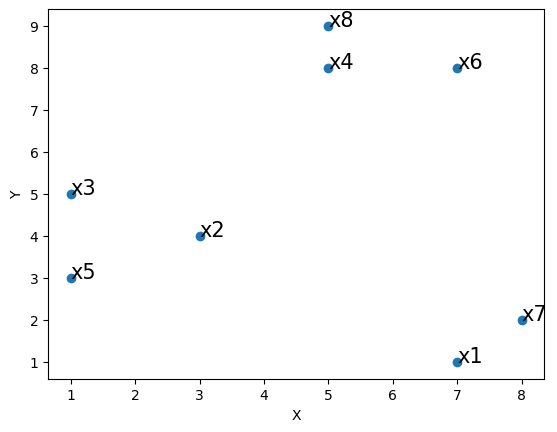

In [2]:
plt.scatter(kdata.X, kdata.Y)
for i in range(len(kdata.index)):
    plt.text(kdata.loc[labels[i], "X"], kdata.loc[labels[i], "Y"], '%s' % (str(labels[i])), size=15, zorder=1) 
plt.xlabel("X")
plt.ylabel("Y")
plt.show()

In [3]:
kmeans = KMeans(n_clusters=3, init=kdata.loc[["x1", "x2", "x3"], :]).fit(kdata)
print(kmeans.cluster_centers_)
print(kmeans.labels_)
print(kmeans.inertia_)
separation = 0
distance = lambda x1, x2: math.sqrt(((x1.X - x2.X) ** 2) + ((x1.Y - x2.Y) ** 2))
m = kdata.mean()
for i in list(set(kmeans.labels_)):
    mi = kdata.loc[kmeans.labels_ == i, :].mean()
    Ci = len(kdata.loc[kmeans.labels_ == i, :].index)
    separation += Ci * (distance(m, mi) ** 2)
print(separation)

[[7.5        1.5       ]
 [5.66666667 8.33333333]
 [1.66666667 4.        ]]
[0 2 2 1 2 1 0 1]
9.0
106.875


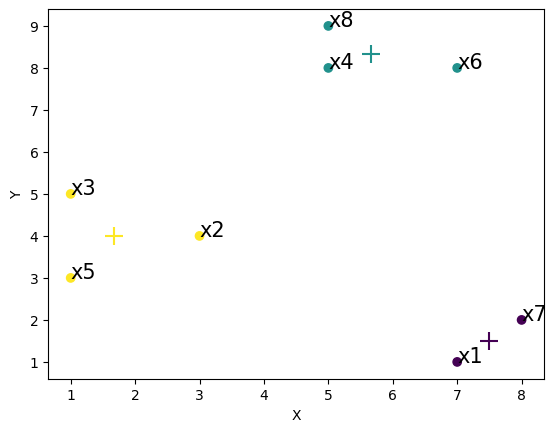

In [4]:
plt.scatter(kdata.X, kdata.Y, c=kmeans.labels_)
for i in range(len(kdata.index)):
    plt.text(kdata.loc[labels[i], "X"], kdata.loc[labels[i], "Y"], '%s' % (str(labels[i])), size=15, zorder=1) 
plt.scatter(kmeans.cluster_centers_[:, 0], kmeans.cluster_centers_[:, 1], marker="+", s=169, c=range(3))
plt.xlabel("X")
plt.ylabel("Y")
plt.show()

In [5]:
cdata = pd.read_csv("./cdata.txt")
target = cdata.loc[:, "Y"]
cdata = cdata.loc[:, ["X1", "X2"]]

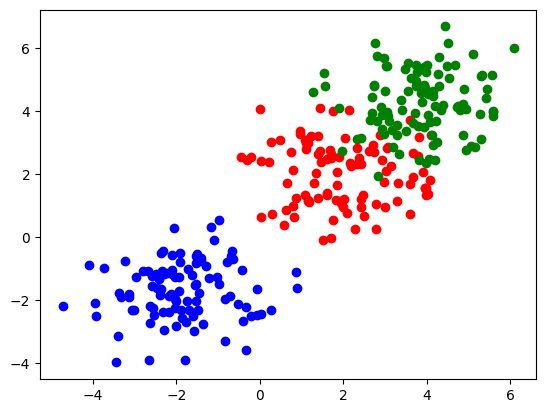

In [6]:
plt.scatter(cdata[(target == 1)].X1, cdata[(target == 1)].X2, c="red", marker="o")
plt.scatter(cdata[(target == 2)].X1, cdata[(target == 2)].X2, c="blue", marker="o")
plt.scatter(cdata[(target == 3)].X1, cdata[(target == 3)].X2, c="green", marker="o")
plt.show()

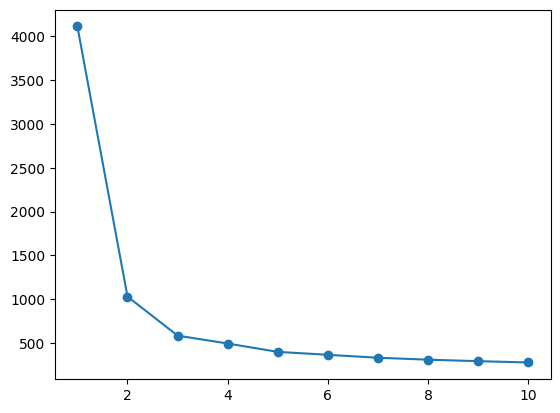

In [7]:
sse = []
for i in range(1, 11):
    sse.append(KMeans(n_clusters=i, init=cdata.loc[0:i-1, :]).fit(cdata).inertia_)
plt.plot(range(1, 11), sse)
plt.scatter(range(1, 11), sse, marker="o")
plt.show()

In [8]:
kmeans = KMeans(n_clusters=3, init=cdata.loc[0:2, :]).fit(cdata)
print(kmeans.cluster_centers_)
print(kmeans.labels_)
print(kmeans.inertia_)
separation = 0
distance = lambda x1, x2: math.sqrt(((x1.X1 - x2.X1) ** 2) + ((x1.X2 - x2.X2) ** 2))
m = cdata.mean()
for i in list(set(kmeans.labels_)):
    mi = cdata.loc[kmeans.labels_ == i, :].mean()
    Ci = len(cdata.loc[kmeans.labels_ == i, :].index)
    separation += Ci * (distance(m, mi) ** 2)
print(separation)

[[-1.8570675  -1.6858993 ]
 [ 1.89654791  1.97842335]
 [ 3.88587923  4.25766929]]
[1 1 1 1 1 2 1 1 1 1 1 1 1 1 2 1 2 1 1 1 2 1 2 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 2 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 1 1 1 1 2 1 1 1 1 1 1 1 1 1 1 1 1 1 1 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2
 2 2 2 2 2 2 2 2 1 2 2 2 2 2 2 2 2 2 2 2 1 2 2 2 2 2 1 2 2 2 2 2 2 2 2 2 2
 2 2 2 2 1 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 1 2 2 2 2 2 2 2 2 2
 2 2 2 2]
585.366220234055
3526.296166392066


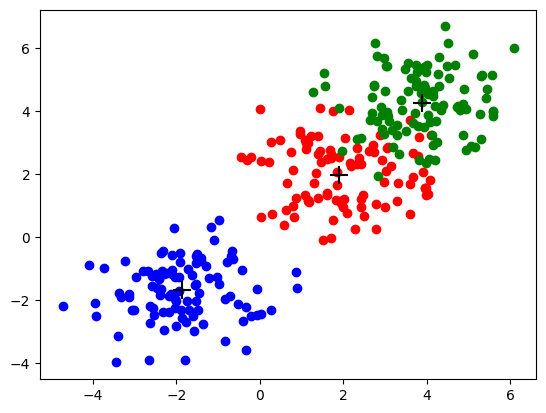

In [9]:
plt.scatter(cdata[(target == 1)].X1, cdata[(target == 1)].X2, c="red", marker="o")
plt.scatter(cdata[(target == 2)].X1, cdata[(target == 2)].X2, c="blue", marker="o")
plt.scatter(cdata[(target == 3)].X1, cdata[(target == 3)].X2, c="green", marker="o")
plt.scatter(kmeans.cluster_centers_[:, 0], kmeans.cluster_centers_[:, 1], marker="+", s=169, color="black")
plt.show()

In [10]:
from sklearn.metrics import silhouette_samples, silhouette_score
print(silhouette_score(cdata, kmeans.labels_))
print(mean(silhouette_samples(cdata, kmeans.labels_)[kmeans.labels_ == 0]))
print(mean(silhouette_samples(cdata, kmeans.labels_)[kmeans.labels_ == 1]))
print(mean(silhouette_samples(cdata, kmeans.labels_)[kmeans.labels_ == 2]))

0.5140944874429041
0.668203657102418
0.41163079817731574
0.4614525715809064


.../site-packages/sklearn/base.py:493: UserWarning: X does not have valid feature names, but KMeans was fitted with feature names
  warnings.warn(


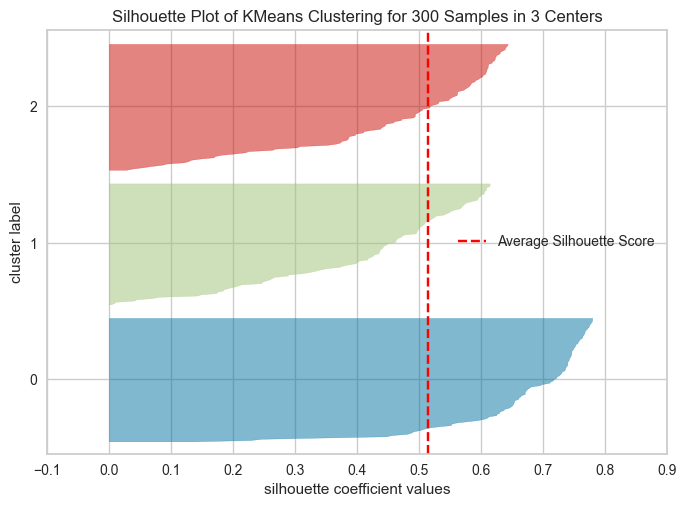

In [11]:
from yellowbrick.cluster import SilhouetteVisualizer
visualizer = SilhouetteVisualizer(kmeans, colors='yellowbrick')
visualizer.fit(cdata)
visualizer.show(); 

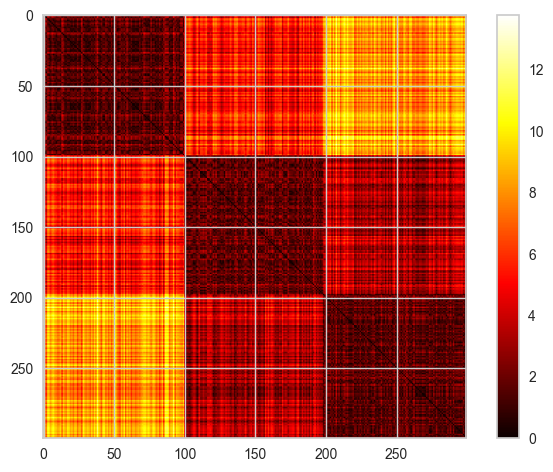

In [12]:
cdata["cluster"] = kmeans.labels_
cdata = cdata.sort_values("cluster").drop("cluster", axis=1)
from scipy.spatial import distance_matrix
dist = distance_matrix(cdata, cdata)
plt.imshow(dist, cmap='hot')
plt.colorbar()
plt.show()

In [13]:
Rank = ["High", "Low", "High", "Low", "Low", "High"]
Topic = ["SE", "SE", "ML", "DM", "ML", "SE"]
conferences = pd.DataFrame({"Rank": Rank, "Topic": Topic})
print(conferences)

   Rank Topic
0  High    SE
1   Low    SE
2  High    ML
3   Low    DM
4   Low    ML
5  High    SE


In [14]:
from sklearn_extra.cluster import KMedoids
from sklearn.preprocessing import OneHotEncoder
encoder = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
encoder = encoder.fit(conferences)
transformed_conferences = encoder.transform(conferences)
kmedoids = KMedoids(n_clusters=3, method="pam").fit(transformed_conferences)

In [15]:
print(kmedoids.cluster_centers_)
print(kmedoids.labels_)
print(conferences.loc[kmedoids.medoid_indices_, :])

[[1. 0. 0. 1. 0.]
 [1. 0. 0. 0. 1.]
 [0. 1. 0. 0. 1.]]
[1 2 0 2 0 1]
   Rank Topic
2  High    ML
5  High    SE
1   Low    SE
